In [46]:
from sklearn.datasets import fetch_openml
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

In [9]:
df = fetch_openml(data_id=37, as_frame=True).frame

In [10]:
df.shape

(768, 9)

In [11]:
df.head()

,preg,plas,pres,skin,insu,mass,pedi,age,class
0,6,148,72,35,0,33.6,0.627,50,tested_positive
1,1,85,66,29,0,26.6,0.351,31,tested_negative
2,8,183,64,0,0,23.3,0.672,32,tested_positive
3,1,89,66,23,94,28.1,0.167,21,tested_negative
4,0,137,40,35,168,43.1,2.288,33,tested_positive


In [12]:
df.columns = ["Pregnancies", "Glucose", "BloodPressure", "SkinThickness",
             "Insulin", "BMI", "PedigreeScore", "Age", "Target"]

In [13]:
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,PedigreeScore,Age,Target
0,6,148,72,35,0,33.6,0.627,50,tested_positive
1,1,85,66,29,0,26.6,0.351,31,tested_negative
2,8,183,64,0,0,23.3,0.672,32,tested_positive
3,1,89,66,23,94,28.1,0.167,21,tested_negative
4,0,137,40,35,168,43.1,2.288,33,tested_positive


In [16]:
df.isna().sum()

Pregnancies      0
Glucose          0
BloodPressure    0
SkinThickness    0
Insulin          0
BMI              0
PedigreeScore    0
Age              0
Target           0
dtype: int64

In [17]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype   
---  ------         --------------  -----   
 0   Pregnancies    768 non-null    int64   
 1   Glucose        768 non-null    int64   
 2   BloodPressure  768 non-null    int64   
 3   SkinThickness  768 non-null    int64   
 4   Insulin        768 non-null    int64   
 5   BMI            768 non-null    float64 
 6   PedigreeScore  768 non-null    float64 
 7   Age            768 non-null    int64   
 8   Target         768 non-null    category
dtypes: category(1), float64(2), int64(6)
memory usage: 49.0 KB


In [18]:
df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,PedigreeScore,Age
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000


In [19]:
cols_w_wrong_zeros = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']

In [21]:
(df[cols_w_wrong_zeros] == 0).sum()

Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64

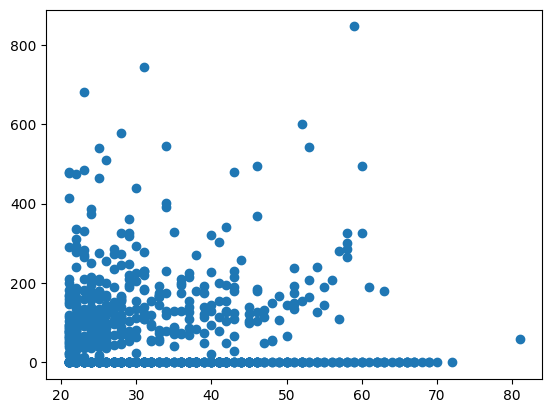

In [23]:
plt.scatter(df['Age'], df['Insulin'])

In [24]:
df['Insulin'].median()

30.5

In [26]:
df[cols_w_wrong_zeros] = df[cols_w_wrong_zeros].replace(0, np.nan)

In [27]:
df['Insulin'].median()

125.0

In [28]:
df.isna().sum()

Pregnancies        0
Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
PedigreeScore      0
Age                0
Target             0
dtype: int64

In [31]:
insulin_median = df['Insulin'].median()
df['Insulin'] = df['Insulin'].fillna(insulin_median)

In [32]:
df.isna().sum()

Pregnancies        0
Glucose            5
BloodPressure     35
SkinThickness    227
Insulin            0
BMI               11
PedigreeScore      0
Age                0
Target             0
dtype: int64

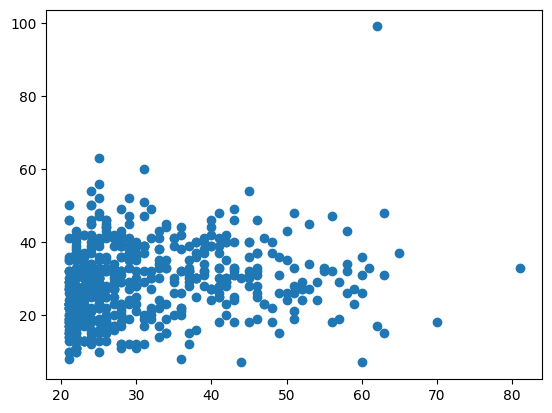

In [34]:
plt.scatter(df['Age'], df['SkinThickness'])

In [35]:
skin_median = df['SkinThickness'].median()
df['SkinThickness'] = df['SkinThickness'].fillna(skin_median)

In [36]:
df.isna().sum()

Pregnancies       0
Glucose           5
BloodPressure    35
SkinThickness     0
Insulin           0
BMI              11
PedigreeScore     0
Age               0
Target            0
dtype: int64

In [37]:
bp_median = df['BloodPressure'].median()
df['BloodPressure'] = df['BloodPressure'].fillna(bp_median)
bmi_median = df['BMI'].median()
df['BMI'] = df['BMI'].fillna(bmi_median)

In [38]:
df.isna().sum()

Pregnancies      0
Glucose          5
BloodPressure    0
SkinThickness    0
Insulin          0
BMI              0
PedigreeScore    0
Age              0
Target           0
dtype: int64

In [39]:
gl_median = df['Glucose'].median()
df['Glucose'] = df['Glucose'].fillna(gl_median)

In [40]:
df.isna().sum()

Pregnancies      0
Glucose          0
BloodPressure    0
SkinThickness    0
Insulin          0
BMI              0
PedigreeScore    0
Age              0
Target           0
dtype: int64

In [41]:
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,PedigreeScore,Age,Target
0,6,148.0,72.0,35.0,125.0,33.6,0.627,50,tested_positive
1,1,85.0,66.0,29.0,125.0,26.6,0.351,31,tested_negative
2,8,183.0,64.0,29.0,125.0,23.3,0.672,32,tested_positive
3,1,89.0,66.0,23.0,94.0,28.1,0.167,21,tested_negative
4,0,137.0,40.0,35.0,168.0,43.1,2.288,33,tested_positive


In [42]:
df['Target'].unique()

['tested_positive', 'tested_negative']
Categories (2, object): ['tested_negative', 'tested_positive']

In [43]:
df['Target'] = df['Target'].map({'tested_positive': 1, 'tested_negative': 0})

In [44]:
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,PedigreeScore,Age,Target
0,6,148.0,72.0,35.0,125.0,33.6,0.627,50,1
1,1,85.0,66.0,29.0,125.0,26.6,0.351,31,0
2,8,183.0,64.0,29.0,125.0,23.3,0.672,32,1
3,1,89.0,66.0,23.0,94.0,28.1,0.167,21,0
4,0,137.0,40.0,35.0,168.0,43.1,2.288,33,1


<Axes: >

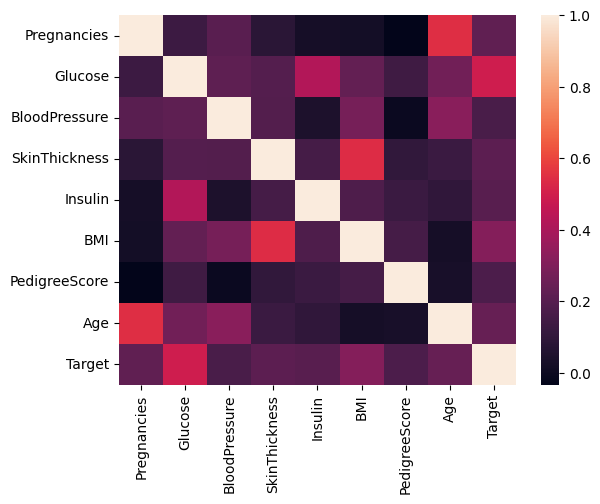

In [47]:
corr = df.corr()
sns.heatmap(corr)

In [49]:
features = df.drop('Target', axis=1)

In [50]:
features.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,PedigreeScore,Age
0,6,148.0,72.0,35.0,125.0,33.6,0.627,50
1,1,85.0,66.0,29.0,125.0,26.6,0.351,31
2,8,183.0,64.0,29.0,125.0,23.3,0.672,32
3,1,89.0,66.0,23.0,94.0,28.1,0.167,21
4,0,137.0,40.0,35.0,168.0,43.1,2.288,33


In [51]:
target = df['Target']

In [52]:
trainX, testX, trainY, testY = train_test_split(features, target, test_size=0.2, random_state=42)

In [53]:
model = RandomForestClassifier()

In [54]:
model.fit(trainX, trainY)

RandomForestClassifier()

In [55]:
prediction = model.predict(testX)

In [56]:
accuracy_score(testY, prediction)

0.7532467532467533